<a href="https://colab.research.google.com/github/M-Harshu/Drug-Discovery-Using-LSTM-Based-Molecular-Generation-and-Multi-Agent-Evaluation-Framework/blob/main/FGAI_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install rdkit-pypi
!pip install pandas numpy tensorflow

ERROR: Could not find a version that satisfies the requirement rdkit-pypi (from versions: none)
ERROR: No matching distribution found for rdkit-pypi


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving 250k_rndm_zinc_drugs_clean_3.csv to 250k_rndm_zinc_drugs_clean_3.csv


In [ ]:
import pandas as pd


smiles = path['smiles'].dropna().tolist()

print(len(smiles))

249455


In [ ]:
!pip install rdkit
from rdkit import Chem

def is_valid(s):
    return Chem.MolFromSmiles(s) is not None

smiles = [s for s in smiles if is_valid(s)]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.0/37.0 MB 17.8 MB/s eta 0:00:00


In [ ]:
PAD = '_'

chars = sorted(list(set(''.join(smiles)) | {PAD}))
char_to_idx = {c:i for i,c in enumerate(chars)}
idx_to_char = {i:c for c,i in char_to_idx.items()}

In [ ]:
max_len = 30
batch_size = 256

In [ ]:
import numpy as np

def data_generator(smiles, batch_size):
    while True:
        X_batch = []
        y_batch = []

        for s in smiles:
            for i in range(min(len(s)-1, 10)):  # limit expansion
                seq = s[:i+1].ljust(max_len, PAD)
                X_batch.append([char_to_idx[c] for c in seq])
                y_batch.append(char_to_idx[s[i+1]])

                if len(X_batch) == batch_size:
                    yield np.array(X_batch), np.array(y_batch)
                    X_batch, y_batch = [], []

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Embedding

model = Sequential([
    Embedding(len(chars), 64, input_length=max_len),
    LSTM(128),
    Dense(len(chars), activation='softmax')
])

model.compile(loss='sparse_categorical_crossentropy', optimizer='adam')

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [ ]:
steps_per_epoch = len(smiles) // batch_size

model.fit(
    data_generator(smiles, batch_size),
    steps_per_epoch=steps_per_epoch,
    epochs=50
)

Epoch 1/50
974/974 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - loss: 2.1295
Epoch 2/50
974/974 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - loss: 1.0654
Epoch 3/50
974/974 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - loss: 0.9605
Epoch 4/50
974/974 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - loss: 0.9210
Epoch 5/50
974/974 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 0.8929
Epoch 6/50
974/974 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - loss: 0.8699
Epoch 7/50
974/974 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - loss: 0.8601
Epoch 8/50
974/974 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - loss: 0.8431
Epoch 9/50
974/974 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - loss: 0.8357
Epoch 10/50
974/974 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - loss: 0.8295
Epoch 11/50
974/974 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - loss: 0.8233
Epoch 12/50
974/974 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - loss: 0.8181
Epoch 13/50
974/974 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - loss: 0.8145
Epoch 14/50
974/974 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - loss: 0.8131
Epoch 15/50
974/974 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - l

In [ ]:
model.save("molecule_model.h5")

In [ ]:
allowed_chars = set(char_to_idx.keys())

def clean_smiles(sm):
    return ''.join([c for c in sm if c in allowed_chars])

In [ ]:
import numpy as np


# Sampling function (stable)
def sample(preds, temperature=0.3):
    preds = np.log(preds + 1e-8) / temperature
    preds = np.exp(preds)
    preds = preds / np.sum(preds)
    return np.random.choice(len(preds), p=preds)




# Generate SMILES (with strict control)
def generate_smiles(seed, length=30):
    s = seed


    for _ in range(length):
        seq = s[:max_len].ljust(max_len, PAD)
        x = np.array([[char_to_idx.get(c, 0) for c in seq]])


        preds = model.predict(x, verbose=0)[0]


        next_idx = sample(preds, temperature=0.3)
        next_char = idx_to_char[next_idx]


        # STOP CONDITIONS (VERY IMPORTANT)
        if next_char == PAD:
            break


        if next_char not in char_to_idx:
            break


        if next_char in ['[', ']', '@', '/', '\\']:
            break


        s += next_char


        if len(s) > max_len:
            break


    return s




# CLEAN FUNCTION
allowed_chars = set(char_to_idx.keys())


def clean_smiles(sm):
    return ''.join([c for c in sm if c in allowed_chars])




# SAFE SEEDS
seeds = ["CC", "CCC", "COC", "CCO"]


# GENERATE MOLECULES
generated = [clean_smiles(generate_smiles(seed=np.random.choice(seeds))) for _ in range(500)]


# REMOVE SHORT + DUPLICATES
generated = [g for g in generated if len(g) > 5]
generated = list(set(generated))


# PRINT OUTPUT
print("Generated Molecules:")
for g in generated:
    print(g)


Generated Molecules:
CC(C)CCC(=O)N1CCC(C(=O))N(C))Cr
CCOc1ccc(CNC(=O)CNC(=O)N)N
CCOc1ccc(NC(=O)C(=O)N(C)C(=
CC(C)CC
COC(=O)c1ccc(CN2CCN(C)c1
COC(=O)c1ccc(Cl)ccc(N)cc(=H
COC(=O)C1=C(N)CN(C)C(=O)N)csH
r
CCCCCNC(=O)c1ccc(C(=O))N(C))2rr
COC(=O)c1cccc(CN2CC
CCOc1ccc(NC(=O)Nc2ccc(-n1nS3)Hr
CCOc1ccc(C(=O)c1ccc(-n1cnn1H
CC(C)CCNC(=O)NC(=O)CN(C)C)(S)Hr
CC(C)CCNC(=O)CNC(=O)N1CCC(c1nFr
CC(C)(C)OC(=O)Nc1ccc(-c3cnn3H
COC(=O)c1ccc(CN2CCC(C)(O)))))))
CCCCC(=O)N1CCC
CC(C)CCNC(=O)NC(=O)CN(C)C(=
COC(=O)C1=C(N)=C(O)(O)CC1CCN)Hr
CCCCNC(=O)c1ccc(
CC(C)(C)C(=O)N1CCC(C(=
CCOc1ccccc1C
CCOC(=O)c1ccc(CN2CCC(C)(O))))Hr
CC(C)CC(=O)N1CCC(C(=O))N
COCCNC(=O)CNC(=O)C1CCC(C))HH
COCCn1c(C)cc(NC(=O)C1CCC(
COC(=O)c1ccc(C(=O)N(C)c1n
CCOc1ccc(NC(=O)CN(C)C(=O
COC(=O)c1ccccc1-c1C(=O))c(N))Hr
CCCCN1C(=O)
CCOc1ccccc1NC(=O)N(C)C(=
COC(=O)C1=C(N)nnc(N)c1n
CC(C)(C)c1ccc(NC(=O)N(C)C)(=
COC(=O)CCCC(=O)Nc1ccc(-nn1n3H)H
CC(C)c1ccc(CNC(=O)
CCCCNC(=O)c1ccc(C
CCCC(=O)N1CCC(C(=O)N
CCOC(=O)c1ccc(C2CC(=O))N(C))CHr
CC(C)CN(C)C(=O)CNC(=O)N)N

In [ ]:
from rdkit import Chem


valid_raw = []

for sm in generated:
    mol = Chem.MolFromSmiles(sm)
    if mol is not None:
        valid_raw.append(sm)


print("Valid molecules:", len(valid_molecules))
print(valid_molecules)

valid_molecules = list(set(valid_raw))
valid_molecules = [m for m in valid_molecules if len(m) > 5]

Valid molecules: 15
['CC(C)(C)', 'CCOc1ccccc1C', 'CC(C)CNC(=O)NC(=O)c1ccccc1O', 'CCCCN(C)C(=O)', 'CC(C)CC', 'COC(=O)c1ccccc1', 'CCC(CC)', 'COC(=O)C', 'COC(=O)', 'CCCCCC', 'CC(C)C', 'CCOC(=O)', 'CCCCCCNC(=O)C', 'CC(C)CCC', 'CCCCNC(=O)CNC(=O)N']


[16:31:02] SMILES Parse Error: extra close parentheses while parsing: CC(C)CCC(=O)N1CCC(C(=O))N(C))Cr
[16:31:02] SMILES Parse Error: check for mistakes around position 29:
[16:31:02] (=O)N1CCC(C(=O))N(C))Cr
[16:31:02] ~~~~~~~~~~~~~~~~~~~~^
[16:31:02] SMILES Parse Error: Failed parsing SMILES 'CC(C)CCC(=O)N1CCC(C(=O))N(C))Cr' for input: 'CC(C)CCC(=O)N1CCC(C(=O))N(C))Cr'
[16:31:02] SMILES Parse Error: unclosed ring for input: 'CCOc1ccc(CNC(=O)CNC(=O)N)N'
[16:31:02] SMILES Parse Error: syntax error while parsing: CCOc1ccc(NC(=O)C(=O)N(C)C(=
[16:31:02] SMILES Parse Error: check for mistakes around position 27:
[16:31:02] cc(NC(=O)C(=O)N(C)C(=
[16:31:02] ~~~~~~~~~~~~~~~~~~~~^
[16:31:02] SMILES Parse Error: extra open parentheses while parsing: CCOc1ccc(NC(=O)C(=O)N(C)C(=
[16:31:02] SMILES Parse Error: check for mistakes around position 9:
[16:31:02] CCOc1ccc(NC(=O)C(=O)N(C)C(=
[16:31:02] ~~~~~~~~^
[16:31:02] SMILES Parse Error: Failed parsing SMILES 'CCOc1ccc(NC(=O)C(=O)N(C)C(=' for input: 

In [ ]:
from rdkit import Chem
from rdkit.Chem import Descriptors

def drug_score(sm):
    mol = Chem.MolFromSmiles(sm)

    mw = Descriptors.MolWt(mol)
    logp = Descriptors.MolLogP(mol)
    h_donors = Descriptors.NumHDonors(mol)
    h_acceptors = Descriptors.NumHAcceptors(mol)

    score = 0
    if mw < 500: score += 1
    if logp < 5: score += 1
    if h_donors <= 5: score += 1
    if h_acceptors <= 10: score += 1

    return score / 4

In [ ]:
def toxicity(sm):
    return len(sm) / 50   # simple proxy

In [ ]:
results = []

for sm in valid_molecules:
    d = drug_score(sm)
    t = toxicity(sm)

    score = d - t

    results.append((sm, d, t, score))

# Sort by best score
results = sorted(results, key=lambda x: x[3], reverse=True)

# Print results
print("Final Ranked Molecules:\n")

for sm, d, t, s in results:
    print(f"Molecule: {sm}")
    print(f"Drug Score: {d:.2f}, Toxicity: {t:.2f}, Final Score: {s:.2f}")
    print("-"*40)

Final Ranked Molecules:

Molecule: CCCCCC
Drug Score: 1.00, Toxicity: 0.12, Final Score: 0.88
----------------------------------------
Molecule: CC(C)C
Drug Score: 1.00, Toxicity: 0.12, Final Score: 0.88
----------------------------------------
Molecule: CC(C)CC
Drug Score: 1.00, Toxicity: 0.14, Final Score: 0.86
----------------------------------------
Molecule: CCC(CC)
Drug Score: 1.00, Toxicity: 0.14, Final Score: 0.86
----------------------------------------
Molecule: COC(=O)
Drug Score: 1.00, Toxicity: 0.14, Final Score: 0.86
----------------------------------------
Molecule: CC(C)(C)
Drug Score: 1.00, Toxicity: 0.16, Final Score: 0.84
----------------------------------------
Molecule: COC(=O)C
Drug Score: 1.00, Toxicity: 0.16, Final Score: 0.84
----------------------------------------
Molecule: CCOC(=O)
Drug Score: 1.00, Toxicity: 0.16, Final Score: 0.84
----------------------------------------
Molecule: CC(C)CCC
Drug Score: 1.00, Toxicity: 0.16, Final Score: 0.84
---------------

In [ ]:
results = []

for sm in valid_molecules:
    d = drug_score(sm)
    t = toxicity(sm)
    score = d - t

    results.append((sm, d, t, score))

# Sort by highest score
results = sorted(results, key=lambda x: x[3], reverse=True)

# BEST molecule
best = results[0]

print("\n🏆 BEST MOLECULE:")
print("Molecule:", best[0])
print("Drug Score:", round(best[1], 2))
print("Toxicity:", round(best[2], 2))
print("Final Score:", round(best[3], 2))


🏆 BEST MOLECULE:
Molecule: CCCCCC
Drug Score: 1.0
Toxicity: 0.12
Final Score: 0.88


In [ ]:
print("\n--- Evaluation Metrics ---")

# 1️⃣ Validity
validity = len(valid_raw) / len(generated)
print("Validity:", round(validity, 3))

# 2️⃣ Uniqueness
uniqueness = len(set(generated)) / len(generated)
print("Uniqueness:", round(uniqueness, 3))

# 3️⃣ Novelty
train_set = set(smiles)   # your training data
novel = [m for m in valid_molecules if m not in train_set]

novelty = len(novel) / len(valid_molecules) if valid_molecules else 0
print("Novelty:", round(novelty, 3))

# 4️⃣ Average Drug Score
scores = [drug_score(m) for m in valid_molecules]
avg_score = sum(scores) / len(scores) if scores else 0

print("Avg Drug Score:", round(avg_score, 3))


--- Evaluation Metrics ---
Validity: 0.062
Uniqueness: 1.0
Novelty: 1.0
Avg Drug Score: 1.0


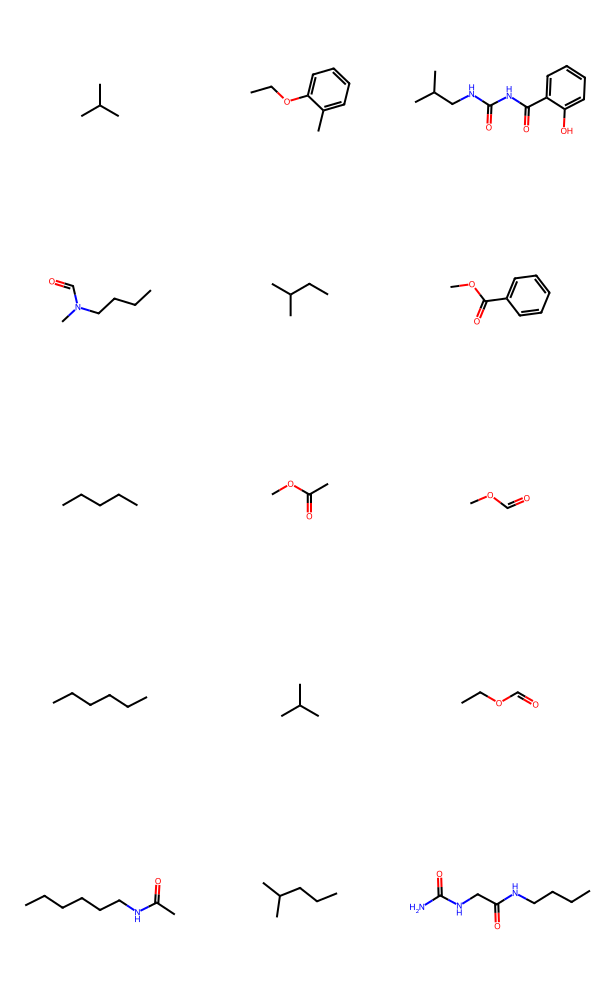

In [ ]:
from rdkit.Chem import Draw

mols = [Chem.MolFromSmiles(sm) for sm in valid_molecules]
Draw.MolsToGridImage(mols)

In [ ]:
print("\n--- Advanced Metrics (%) ---")

total_valid = len(valid_molecules)

# 1️⃣ Drug-like %
drug_like = [m for m in valid_molecules if drug_score(m) >= 0.75]
drug_like_pct = (len(drug_like) / total_valid * 100) if total_valid else 0

# 2️⃣ Non-drug-like %
non_drug_like_pct = 100 - drug_like_pct

# 3️⃣ Average Toxicity (already a value, keep as is or convert to %)
tox_scores = [toxicity(m) for m in valid_molecules]
avg_toxicity = (sum(tox_scores) / len(tox_scores) * 100) if tox_scores else 0

# 4️⃣ Novel %
train_set = set(smiles)
novel_molecules = [m for m in valid_molecules if m not in train_set]
novel_pct = (len(novel_molecules) / total_valid * 100) if total_valid else 0

print("Drug-Like Molecules (%):", round(drug_like_pct, 2))
print("Non-Drug-Like Molecules (%):", round(non_drug_like_pct, 2))
print("Average Toxicity (%):", round(avg_toxicity, 2))
print("Novel Molecules (%):", round(novel_pct, 2))


--- Advanced Metrics (%) ---
Drug-Like Molecules (%): 100.0
Non-Drug-Like Molecules (%): 0.0
Average Toxicity (%): 21.73
Novel Molecules (%): 100.0


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("basu369victor/zinc250k")

print("Path to dataset files:", path)

100%|██████████| 8.60M/8.60M [00:00<00:00, 11.0MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/basu369victor/zinc250k/versions/1
